# E1 Masques PRMI contre masques corrigés

Que vaut la correction manuelle des masques, à images égales ? Même entraînement que le notebook 03 (mêmes 149 images, mêmes réglages, même graine), avec les **masques PRMI d'origine** (rectangles, fentes, racines oubliées) au lieu des masques corrigés. Les deux modèles sont évalués sur le même val corrigé.

**L'essentiel** : les masques PRMI font un peu moins bien, mais de peu : -0,025 de Dice par image (31 images sur 44 moins bonnes), -0,012 de Dice global, 80 % des racines trouvées contre 84 %. Corriger aide, mais un modèle apprend déjà beaucoup des rectangles : ajouter des images non corrigées est une piste rentable (notebook 04).

Le Dice train est mesuré sur les masques d'entraînement de chaque essai (PRMI ici) : il ne se compare pas d'un essai à l'autre.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import matplotlib.pyplot as plt
import pandas as pd

from prmi import viz
from prmi.dataset import load_lot
from prmi.train import compare_runs, load_run, predict, run_exists, train

viz.apply_style()
pd.set_option('display.width', 180)
%config InlineBackend.figure_formats = ['jpeg']
plt.rcParams['figure.dpi'] = 90

REFERENCE = 'unet_effb0_s2_aug'      # masques corrigés
NAME = 'unet_effb0_s2_aug_origine'   # masques d'origine
SCALE = 2

## 1. Données

Mêmes images que le notebook 03 ; seuls les masques du train changent.

In [2]:
train_items = load_lot('train', SCALE, masks='origine')
val_items = load_lot('val', SCALE)   # masques corrigés
print('train', len(train_items), 'images, dont', sum(it['mask'].any() for it in train_items), 'avec racine (masques d\'origine)')
print('val  ', len(val_items), 'images, dont', sum(it['mask'].any() for it in val_items), 'avec racine (masques corrigés)')

train 149 images, dont 85 avec racine (masques d'origine)
val   74 images, dont 44 avec racine (masques corrigés)


## 2. Entraînement

Environ 1 h 15. Mêmes réglages que la référence (`augment=True`, graine 0). Si l'essai existe déjà, il n'est pas relancé.

In [3]:
if run_exists(NAME):
    print('Entraînement déjà présent, relecture de', NAME)
else:
    train(train_items, val_items, NAME, augment=True)

cpu, 926,521 paramètres utilisés, 149 images train, 74 images val, 37 batchs par époque
  1/100  perte train 0.521  val 0.265  Dice train 0.506  val 0.483  global 0.580  racines 66%  fantômes 51  longueur 0.25  images vides touchées 0.27  lr 1.0e-04 / 1.0e-03  49 s
  2/100  perte train 0.341  val 0.202  Dice train 0.507  val 0.494  global 0.597  racines 56%  fantômes 20  longueur 0.44  images vides touchées 0.20  lr 1.0e-04 / 1.0e-03  43 s
  3/100  perte train 0.285  val 0.169  Dice train 0.570  val 0.554  global 0.652  racines 67%  fantômes 34  longueur 0.35  images vides touchées 0.33  lr 1.0e-04 / 1.0e-03  48 s
  4/100  perte train 0.284  val 0.154  Dice train 0.612  val 0.594  global 0.674  racines 73%  fantômes 103  longueur 0.23  images vides touchées 0.60  lr 1.0e-04 / 1.0e-03  47 s
  5/100  perte train 0.263  val 0.154  Dice train 0.627  val 0.590  global 0.667  racines 73%  fantômes 83  longueur 0.21  images vides touchées 0.60  lr 1.0e-04 / 1.0e-03  47 s
  6/100  perte train 

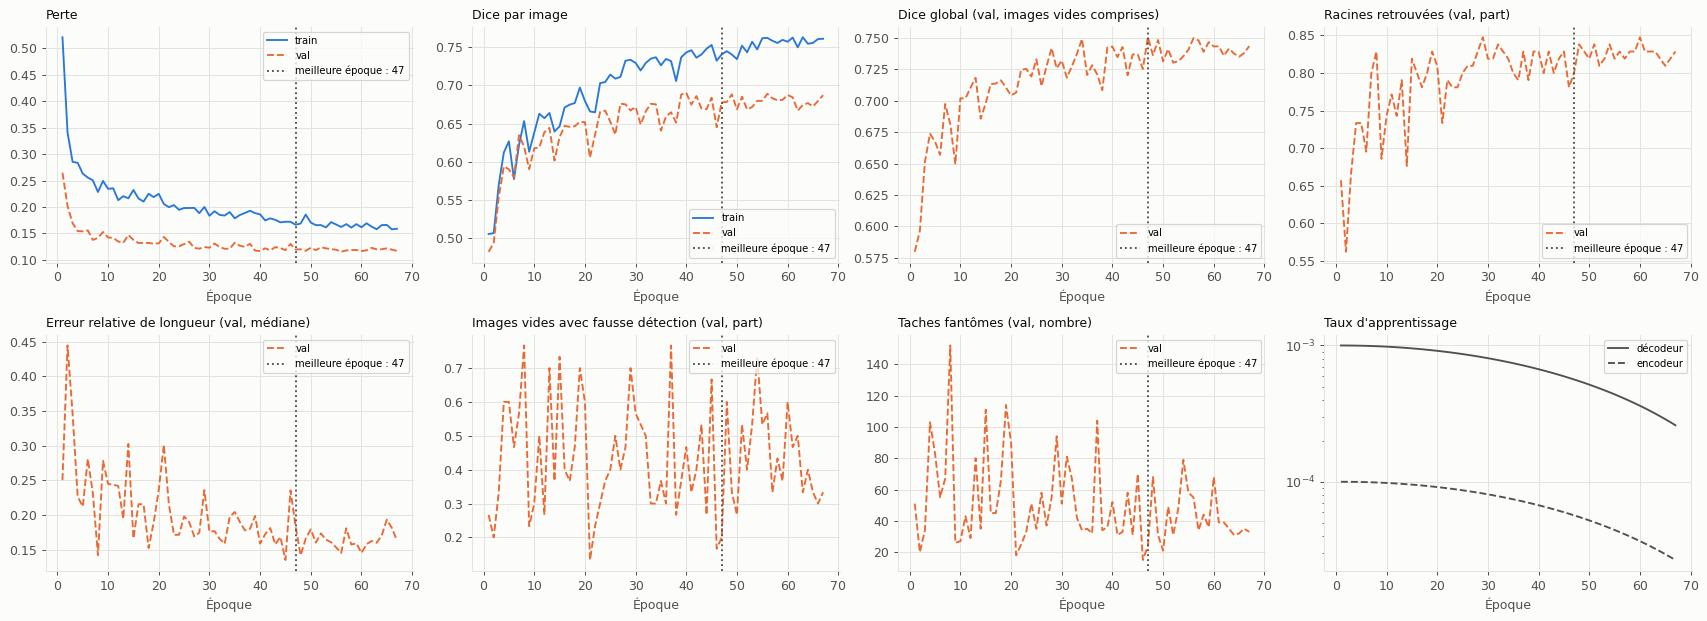

In [4]:
model, history, best_epoch, per_image = load_run(NAME)
device = next(model.parameters()).device
viz.plot_history(history, best_epoch);

## 3. Comparaison avec la référence (masques corrigés)

Moyennes du val à la meilleure époque de chaque essai, puis Dice image par image sur les 44 images du val avec racine (écart = origine moins corrigés ; négatif : les masques d'origine font moins bien).

In [5]:
summary, paired, delta = compare_runs(REFERENCE, NAME)
display(summary.round(3))
paired.round(4)

,epoch,train_dice,dice,global_dice,roots_found,ghosts,length_err,fp_empty
unet_effb0_s2_aug,82.0,0.814,0.703,0.763,0.838,39.0,0.150,0.4
unet_effb0_s2_aug_origine,47.0,0.741,0.678,0.751,0.800,24.0,0.184,0.2


images          44.0000
écart moyen     -0.0248
écart médian    -0.0125
b meilleur      13.0000
b moins bon     31.0000
p (Wilcoxon)     0.0252
dtype: float64

## 4. Images

Référence corrigée à gauche, prédiction de l'essai sur masques d'origine à droite.

In [ ]:
preds = {it['name']: predict(model, it, device) for it in val_items}
viz.browse_predictions(val_items, preds, per_image)

interactive(children=(IntSlider(value=0, continuous_update=False, description='Image', layout=Layout(width='80…

## 5. À retenir

- **Écart faible mais net** en faveur des masques corrigés (p = 0,025 sur le Dice par image).
- **Le modèle entraîné sur rectangles prédit moins** : arrêt plus tôt (meilleure époque 47), moins d'images vides touchées (20 % contre 40 %), mais aussi moins de racines trouvées.
- **Conclusion** : la quantité d'images peut compenser la qualité des masques. C'est l'hypothèse du notebook 04.